# Unit 9: CNN object recognition on CIFAR-10

The module's notebook is kept, with one marked fix. Everything under **My changes** is mine.

**Task:** run the CNN, review its sections, and change the test image from `x_test[16]` to other indexes
(1 to 15) to see whether the model predicts correctly. The Wall (2019) reading on the ethics of this
technology is answered in my written reflection, not here.

*The comments at the end of the module's own code lines are mine, added to explain what each line does. The module's original comments are unchanged.*

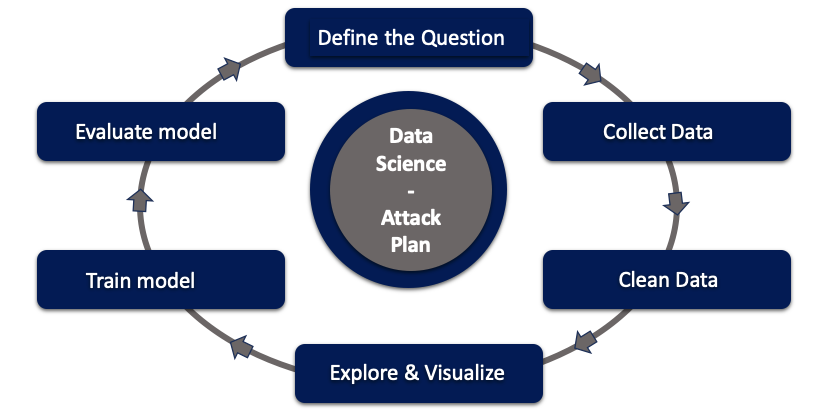

# Convolutional Neural Networks (CNN) - Object Recognition 

# Imports

In [1]:
from numpy.random import seed                       # fixes numpy's random numbers
seed(888)                                           # numpy seed

#from tensorflow import set_random_seed
#set_random_seed(4112)
import tensorflow                                   # deep learning library
tensorflow.random.set_seed(112)                     # TensorFlow seed (CPU runs still vary slightly)

2026-10-12 11:39:30.853707: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 11:39:30.894568: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-12 11:39:31.877448: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import os                                           # files and folders
import numpy as np                                  # arrays and maths
import itertools                                    # looping helpers

import tensorflow as tf                             # deep learning library
import keras                                        # the neural network API on top of TensorFlow
from keras.datasets import cifar10 # importing the dataset

from keras.models import Sequential       #to define model/ layers
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten  # the four layer types used

from sklearn.metrics import confusion_matrix        # true class vs predicted class counts

# To Explore the images
from IPython.display import display                 # show an image inline
from keras.preprocessing.image import array_to_img  # turn an array back into a picture

from tensorflow.keras.utils import to_categorical   # one-hot encoding of the labels

import matplotlib.pyplot as plt                     # plotting
%matplotlib inline

In [3]:
import pandas as pd                                 # tables

We are using Tensorflow to power Keras

# Get the Dataset

CIFAR-10  is an established computer-vision dataset used for object recognition. It is a subset of the 80 million tiny images dataset and consists of 60,000 32x32 color images containing one of 10 object classes, with 6000 images per class. It was collected by Alex Krizhevsky, Vinod Nair, and Geoffrey Hinton.
The dataset is popularly used to train image classification models

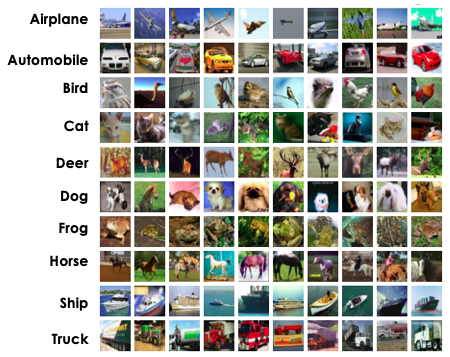

In [4]:
# Getting the dataset as a Tuple

(x_train_all, y_train_all), (x_test, y_test) = cifar10.load_data()  # 50,000 training and 10,000 test images

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3314s 19us/step


# Constants

In [5]:
LABEL_NAMES = ['airplane', 'automobile','bird','cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']  # class number -> name

# Exploring the Data

Lets look at the first image in the dataset

In [6]:
x_train_all.shape                                   # images x height x width x colour channels

(50000, 32, 32, 3)

In [7]:
x_train_all[0]                                      # first image as raw pixel numbers 0 to 255

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

In [8]:
x_train_all[0].shape                                # 32 x 32 x 3

(32, 32, 3)

#### Using ipython to display the image

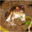

In [9]:
# To use the ipython display to view an image

pic = array_to_img(x_train_all[0])                  # back to a picture
display(pic)                                        # show it at its real size

#### Using Matplotlib to view the image

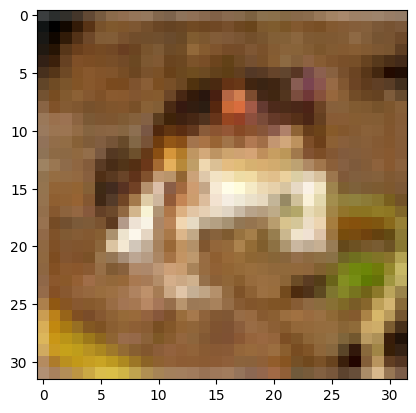

In [10]:
plt.imshow(x_train_all[0])                          # show it enlarged


In [11]:
# To check the label 
y_train_all.shape                                   # one label per image

(50000, 1)

In [12]:
# Note that in the image above the index 1 corresponds to "Automobile" 
# we have a 2 dimension numpy array; that is why we also include " [0] "

y_train_all[0][0]                                   # label of the first image, as a number

np.uint8(6)

In [13]:
# Using the lable names to get the actual names of classes

LABEL_NAMES[y_train_all[0][0]]                      # and as a name

'frog'

### The shape of the image
    * 32, 32 is the weight and the height
    * 3 is the number of channels (These are the number of colors): Red, Green & Blue (RGB)
    
 * x_train_all.shape  >>> (50000, 32, 32, 3)
     * this means we have 50,000 entries | then 32x32  weight and height| 3 colors (RGB)

In [14]:
x_train_all.shape                                   # images x height x width x colour channels

(50000, 32, 32, 3)

In [15]:
number_of_images, x, y, c = x_train_all.shape       # unpack the four sizes
print(f'Number of images = {number_of_images} \t| width = {x} \t| height = {y} \t| channels = {c}')  # show them

Number of images = 50000 	| width = 32 	| height = 32 	| channels = 3


In [16]:
x_test.shape                                        # 10,000 test images

(10000, 32, 32, 3)

# Preprocess Data

#### * We need to preprocess our data so that it is easier to feed it to our neural network.
 

### Scalling both x_train and test


In [17]:
x_train_all =x_train_all / 255.0                    # scale pixels to 0-1 so training is stable

In [18]:
x_test =  x_test / 255.0                            # same for test

In [19]:
y_test                                              # show test labels

array([[3],
       [8],
       [8],
       ...,
       [5],
       [1],
       [7]], shape=(10000, 1), dtype=uint8)

### Creating categorical encoding for the "y " data

In [20]:
# 10 >>> simply means we have 10 classes like we already know (creating the encoding for 10 classes)
y_cat_train_all = to_categorical(y_train_all,10)    # e.g. 6 -> [0,0,0,0,0,0,1,0,0,0]

In [21]:
# 10 >>> simply means we have 10 classes like we already know (creating the encoding for 10 classes)
y_cat_test = to_categorical(y_test,10)              # same for test

In [22]:
y_cat_train_all                                     # show them

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

# Creating the Validation dataset
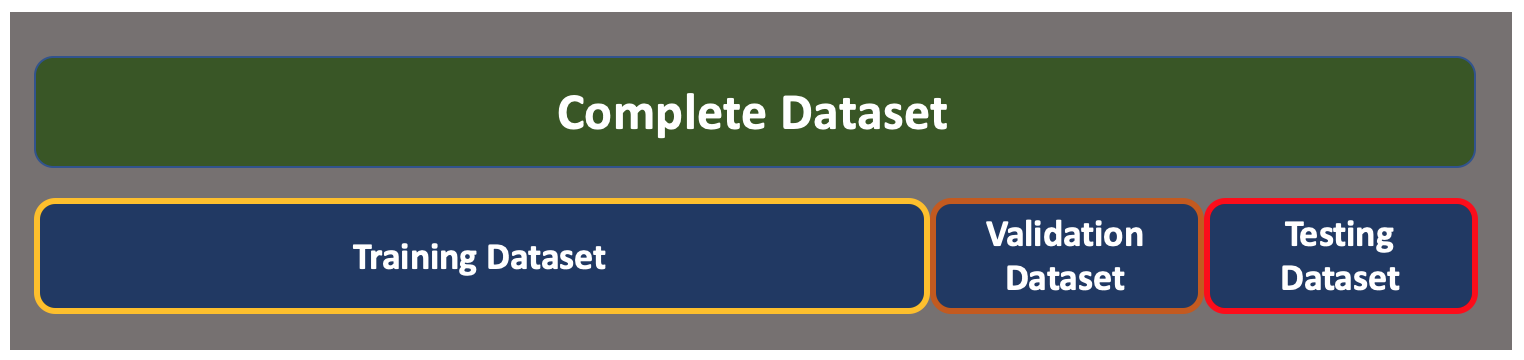

For small data we usually go with:
    * 60% for Training
    * 20% Validation
    * 20% Testing
    
Only the final selected model gets to see the testing data. This helps us to ensure that we have close to real data in real-world when the model is deployed. Only our best model gets to see our testing dataset. Because it will give us a realistic impression of how our model will do in the real world
___

However, if the dataset is enormous.:
    * 1% for is used for validation
    * 1% for is used for testing

In [23]:
VALIDATION_SIZE = 10000                             # hold back 10,000 training images to check progress

In [24]:
# VALIDATION_SIZE = 10,000 as defined above 

x_val = x_train_all[:VALIDATION_SIZE]               # first 10,000 images for validation
y_val_cat = y_cat_train_all[:VALIDATION_SIZE]       # their labels
x_val.shape                                         # check the size

(10000, 32, 32, 3)

In [25]:
y_val_cat                                           # show them

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

<b>NEXT:</b>
* We Create two NumPy arrays x_train and y_train that have the shape(40000, 3072) and (40000,1) respectively. 
* They will contain the last 40000 values from x_train_all and y_train_all respectively

In [26]:
x_train = x_train_all[VALIDATION_SIZE:]             # the other 40,000 for training
y_cat_train= y_cat_train_all[VALIDATION_SIZE:]      # their labels

In [27]:
x_train.shape                                       # check the size

(40000, 32, 32, 3)

In [28]:
y_cat_train                                         # show them

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(40000, 10))

 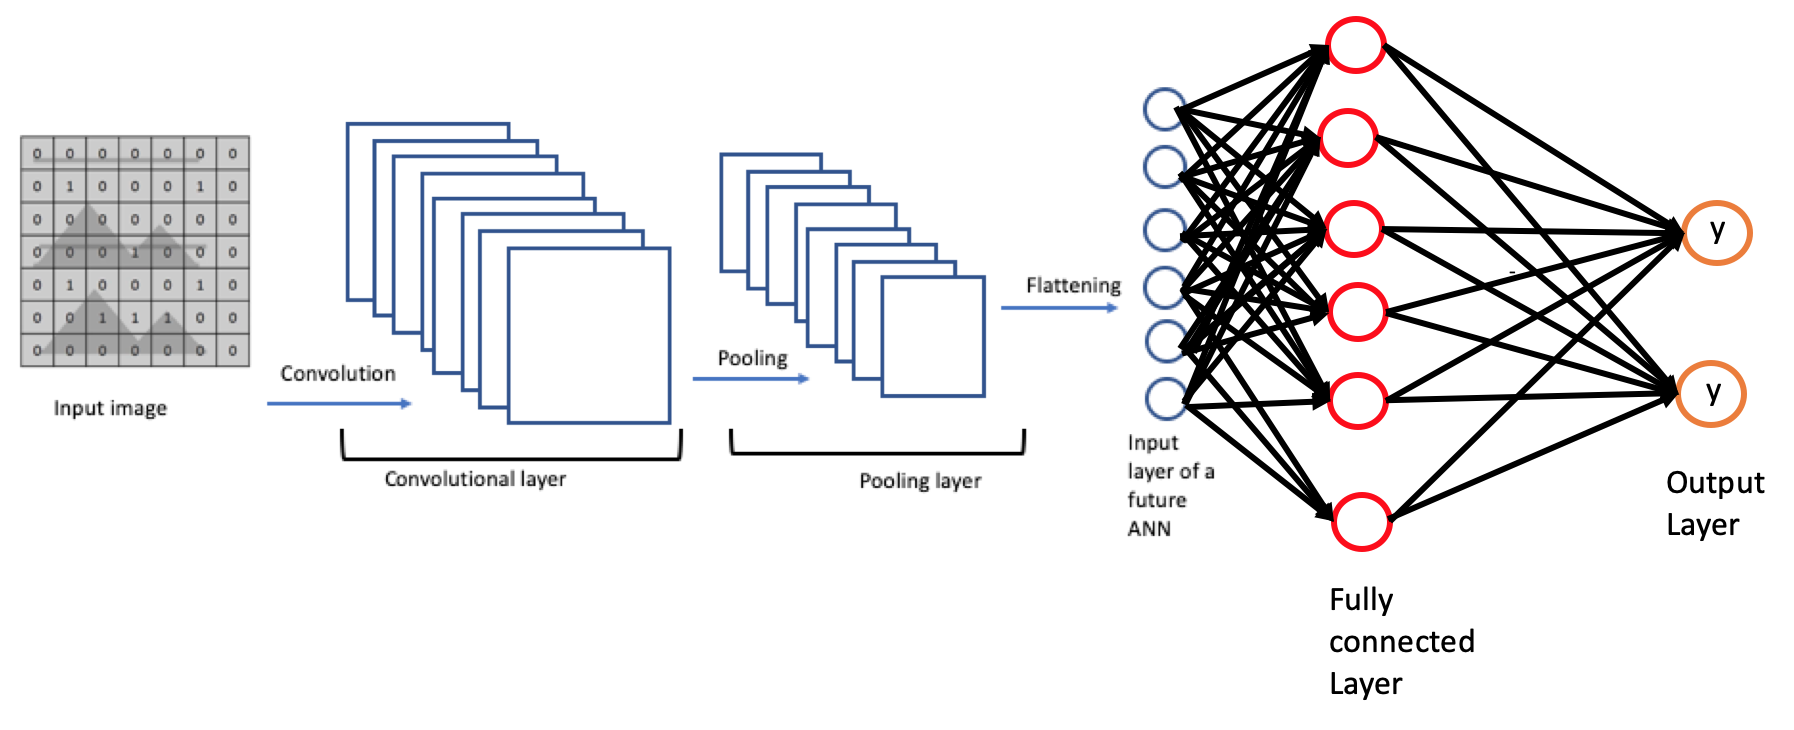
 ## NOTE:
 <h4>* <em>FILTERS: </em>
    Typical values for the number of filters can be determined by the data set's complexity. So essentially the larger the images, the more variety and the more classes you're trying to classify then the more filters you should have.</h4>
   <h4> * Most times people typically pick filter based on powers of 2, for example, 32. However, if you have more complex data like road signs etc. you should be starting with a higher filter value</h4>
   <h4>The default STRIDE value is 1 x 1 pixel</h4>

# BUILDING THE MODEL

In [29]:
model = Sequential()                                # layers stacked one after another

## ************* FIRST SET OF LAYERS *************************

# CONVOLUTIONAL LAYER
model.add(Conv2D(filters=32, kernel_size=(4,4),input_shape=(32, 32, 3), activation='relu',))  # 32 filters of 4x4 pixels; ReLU zeroes negatives
# POOLING LAYER
model.add(MaxPool2D(pool_size=(2, 2)))              # halve the size, keeping the strongest value in each 2x2

## *************** SECOND SET OF LAYERS ***********************
#Since the shape of the data is 32 x 32 x 3 =3072 ... 
#We need to deal with this more complex structure by adding yet another convolutional layer

# *************CONVOLUTIONAL LAYER
model.add(Conv2D(filters=32, kernel_size=(4,4),input_shape=(32, 32, 3), activation='relu',))  # 32 filters of 4x4 pixels; ReLU zeroes negatives
# POOLING LAYER
model.add(MaxPool2D(pool_size=(2, 2)))              # halve the size, keeping the strongest value in each 2x2

# FLATTEN IMAGES FROM 32 x 32 x 3 =3072 BEFORE FINAL LAYER
model.add(Flatten())                                # feature maps -> one long list of numbers

# 256 NEURONS IN DENSE HIDDEN LAYER (YOU CAN CHANGE THIS NUMBER OF NEURONS)
model.add(Dense(256, activation='relu'))            # 256 fully connected neurons

# LAST LAYER IS THE CLASSIFIER, THUS 10 POSSIBLE CLASSES
model.add(Dense(10, activation='softmax'))          # 10 outputs, one probability per class


model.compile(loss='categorical_crossentropy',      # the error measure for one-hot classes
              optimizer='adam',                     # Adam: gradient descent with adaptive step sizes
              metrics=['accuracy'])                 # also report accuracy

/home/z331992/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-12 12:34:52.376067: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [30]:
model.summary()                                     # layers and number of weights

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,610 (881.29 KB)

 Trainable params: 225,610 (881.29 KB)

 Non-trainable params: 0 (0.00 B)

### Adding Early stopping

In [31]:
from tensorflow.keras.callbacks import EarlyStopping  # stops training when it stops improving

In [32]:
early_stop = EarlyStopping(monitor='val_loss',patience=2)  # stop after 2 epochs with no improvement in validation loss

In [33]:
history = model.fit(x_train,y_cat_train,epochs=25,validation_data=(x_val,y_val_cat),callbacks=[early_stop])  # train for up to 25 epochs

Epoch 1/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.4363 - loss: 1.5535 - val_accuracy: 0.5202 - val_loss: 1.3084
Epoch 2/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.5648 - loss: 1.2370 - val_accuracy: 0.5803 - val_loss: 1.1825
Epoch 3/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.6200 - loss: 1.0895 - val_accuracy: 0.6049 - val_loss: 1.1302
Epoch 4/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.6597 - loss: 0.9790 - val_accuracy: 0.6248 - val_loss: 1.0813
Epoch 5/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.6930 - loss: 0.8870 - val_accuracy: 0.6395 - val_loss: 1.0613
Epoch 6/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.7213 - loss: 0.8076 - val_accuracy: 0.6433 - val_loss: 1.0699
Epoch 7/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.7438 - loss: 0.7389 - val_accuracy: 0.6432 - val_loss: 1.1370


In [34]:
model.history.history.keys()                        # what was logged each epoch

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [35]:
metrics = pd.DataFrame(model.history.history)       # the log as a table

In [36]:
metrics                                             # show it

,accuracy,loss,val_accuracy,val_loss
0,0.436325,1.553514,0.5202,1.308363
1,0.564850,1.237035,0.5803,1.182549
2,0.620025,1.089472,0.6049,1.130181
3,0.659725,0.978977,0.6248,1.081299
4,0.692950,0.886998,0.6395,1.061281
5,0.721300,0.807588,0.6433,1.069947
6,0.743800,0.738908,0.6432,1.137020


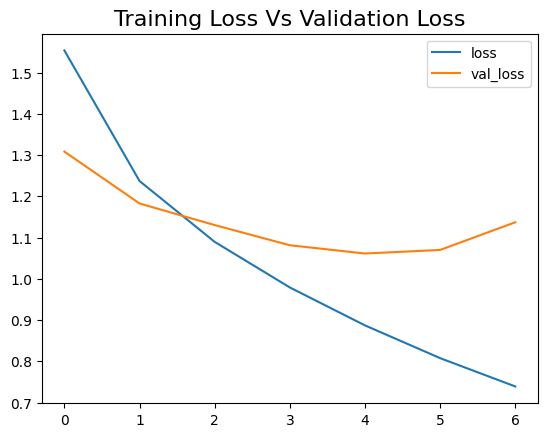

In [37]:
metrics[['loss', 'val_loss']].plot()                # training vs validation loss
plt.title('Training Loss Vs Validation Loss', fontsize=16)  # title
plt.show()                                          # draw

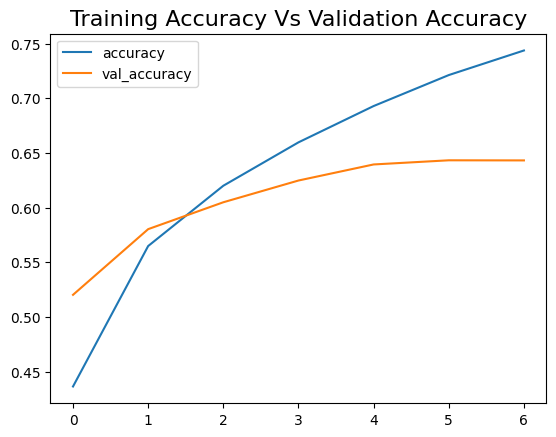

In [38]:
metrics[['accuracy', 'val_accuracy']].plot()        # training vs validation accuracy
plt.title('Training Accuracy Vs Validation Accuracy', fontsize=16)  # title
plt.show()                                          # draw

## Validating on Test Data

In [39]:
model.evaluate(x_test,y_cat_test)                   # loss and accuracy on the 10,000 test images

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6418 - loss: 1.1540


[1.1540181636810303, 0.6417999863624573]

## Classification Report and Confusion Matrix

In [40]:
from sklearn.metrics import classification_report, confusion_matrix  # per-class scores

In [41]:
#predictions = model.predict_classes(x_test)
predictions = np.argmax(model.predict(x_test), axis=-1)  # the class with the highest probability

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [42]:
print(classification_report(y_test,predictions))    # precision, recall and F1 per class

              precision    recall  f1-score   support

           0       0.80      0.58      0.67      1000
           1       0.80      0.75      0.78      1000
           2       0.58      0.51      0.54      1000
           3       0.38      0.63      0.47      1000
           4       0.57      0.63      0.60      1000
           5       0.65      0.36      0.47      1000
           6       0.65      0.80      0.72      1000
           7       0.70      0.71      0.70      1000
           8       0.77      0.75      0.76      1000
           9       0.75      0.69      0.72      1000

    accuracy                           0.64     10000
   macro avg       0.67      0.64      0.64     10000
weighted avg       0.67      0.64      0.64     10000



In [43]:
confusion_matrix(y_test,predictions)                # rows = true class, columns = predicted

array([[576,  37,  76,  52,  51,   8,  26,  21, 106,  47],
       [ 14, 753,   7,  31,   7,   5,  29,  10,  41, 103],
       [ 38,   4, 510, 136, 119,  41,  98,  36,  13,   5],
       [  5,  10,  66, 626,  75,  76,  87,  39,  10,   6],
       [  7,   3,  56, 119, 634,  12,  91,  63,  11,   4],
       [  4,   5,  76, 361,  66, 362,  50,  69,   3,   4],
       [  1,   2,  35,  90,  43,   8, 804,   8,   3,   6],
       [  4,   4,  30, 108,  87,  23,  16, 710,   4,  14],
       [ 52,  31,  18,  54,  21,   9,  18,  10, 749,  38],
       [ 20,  88,  11,  64,   8,   9,  26,  49,  31, 694]])

# Predicting on single image

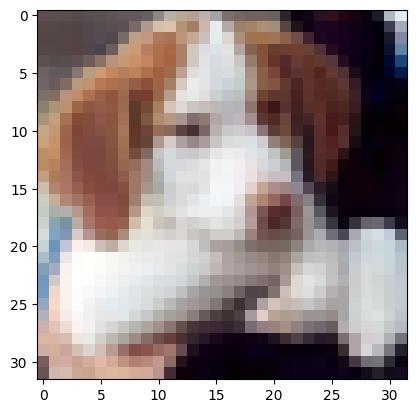

In [44]:
plt.imshow(x_test[16])                              # show test image 16

In [45]:
my_image = x_test[16]                               # pick it

> **Fix (mine):** `predict_classes` was removed from Keras in TensorFlow 2.6, so this line stopped with an AttributeError. The module had already made the same change further up (cell `predictions = np.argmax(...)`), so I used the same pattern here.

In [46]:
# SHAPE --> (num_images,width,height,color_channels)
np.argmax(model.predict(my_image.reshape(1,32,32,3), verbose=0), axis=-1)  # predicted class (reshape adds the batch of 1)

array([5])

In [47]:
LABEL_NAMES[y_test[16][0]]                          # its true class

'dog'

## My changes

### 1. Test images 1 to 16

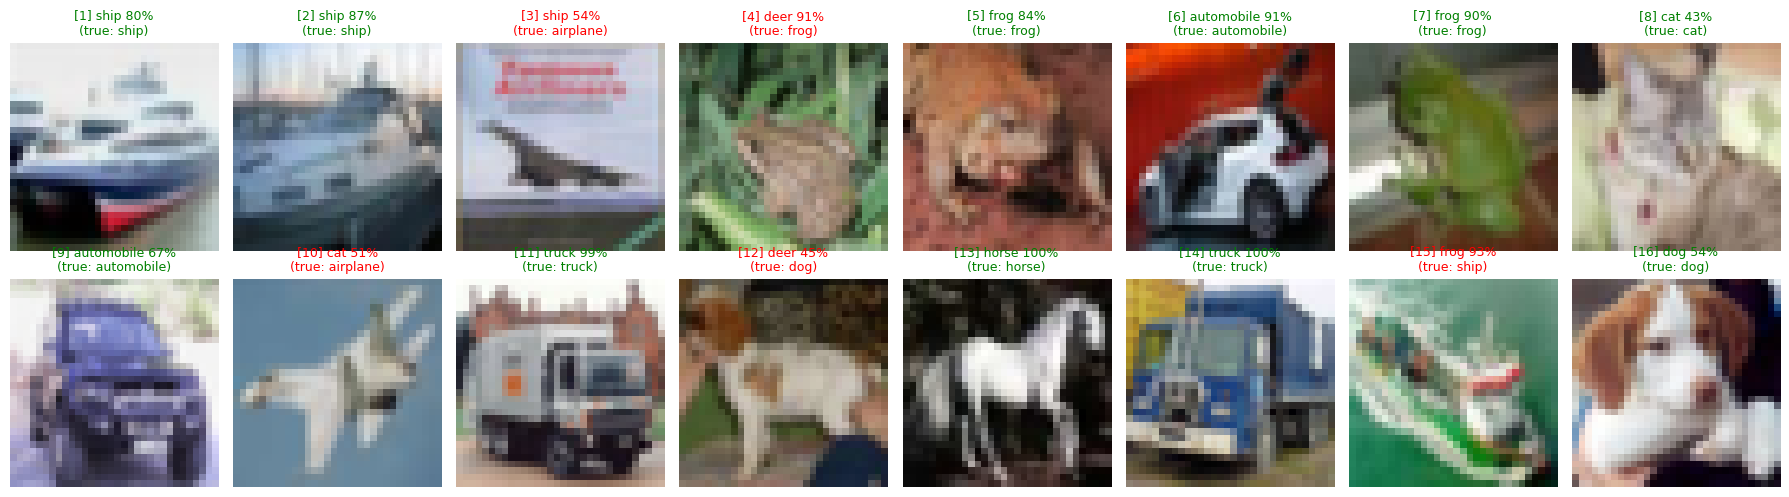

 index true label  predicted confidence correct?
     1       ship       ship        80%      yes
     2       ship       ship        87%      yes
     3   airplane       ship        54%       NO
     4       frog       deer        91%       NO
     5       frog       frog        84%      yes
     6 automobile automobile        91%      yes
     7       frog       frog        90%      yes
     8        cat        cat        43%      yes
     9 automobile automobile        67%      yes
    10   airplane        cat        51%       NO
    11      truck      truck        99%      yes
    12        dog       deer        45%       NO
    13      horse      horse       100%      yes
    14      truck      truck       100%      yes
    15       ship       frog        93%       NO
    16        dog        dog        54%      yes

11 of 16 correct


In [48]:
probs = model.predict(x_test[1:17], verbose=0)       # class probabilities for test images 1 to 16
rows = []                                            # results table
fig, axes = plt.subplots(2, 8, figsize=(18, 5))      # a 2 x 8 grid of pictures
for ax, idx, p in zip(axes.ravel(), range(1, 17), probs):   # each image with its probabilities
    pred, true = int(np.argmax(p)), int(y_test[idx][0])     # the model's top class and the real class
    rows.append((idx, LABEL_NAMES[true], LABEL_NAMES[pred], f"{p[pred]:.0%}", "yes" if pred == true else "NO"))  # one table row per image
    ax.imshow(x_test[idx]); ax.axis("off")           # show the image
    ax.set_title(f"[{idx}] {LABEL_NAMES[pred]} {p[pred]:.0%}\n(true: {LABEL_NAMES[true]})",  # prediction, confidence and truth
                 fontsize=9, color="green" if pred == true else "red")   # green if right, red if wrong
plt.tight_layout(); plt.show()  # tidy the spacing and draw
table = pd.DataFrame(rows, columns=["index", "true label", "predicted", "confidence", "correct?"])   # the same as a table
print(table.to_string(index=False))  # print the table
print(f"\n{(table['correct?'] == 'yes').sum()} of 16 correct")  # how many of the 16 were right

### 2. Where does the model go wrong overall?

In [49]:
cm = confusion_matrix(y_test, predictions)            # rows = true class, columns = predicted class
per_class = pd.Series(cm.diagonal() / cm.sum(axis=1), index=LABEL_NAMES).sort_values()   # correct / total, per class
print("Accuracy per class on the 10,000 test images:")  # heading
print((per_class * 100).round(1).astype(str).add("%").to_string())   # worst first

off = cm.copy(); np.fill_diagonal(off, 0)            # keep only the mistakes (zero out the correct diagonal)
# every (count, true class, predicted class) mistake pair, biggest first, top 5
pairs = sorted(((off[i, j], LABEL_NAMES[i], LABEL_NAMES[j]) for i in range(10) for j in range(10) if off[i, j]), reverse=True)[:5]  # the five biggest (true, predicted) mix-ups
print("\nMost common mistakes (true -> predicted):")  # heading
for n, t, p_ in pairs:  # each mix-up
    print(f"  {t:>10} -> {p_:<10} {n} times")  # true class -> predicted class, and how often

Accuracy per class on the 10,000 test images:
dog           36.2%
bird          51.0%
airplane      57.6%
cat           62.6%
deer          63.4%
truck         69.4%
horse         71.0%
ship          74.9%
automobile    75.3%
frog          80.4%

Most common mistakes (true -> predicted):
         dog -> cat        361 times
        bird -> cat        136 times
        deer -> cat        119 times
        bird -> deer       119 times
       horse -> cat        108 times


### 3. Confident and wrong

Average confidence when right: 83%   when wrong: 63%
Wrong predictions made with over 90% confidence: 381 of 3582


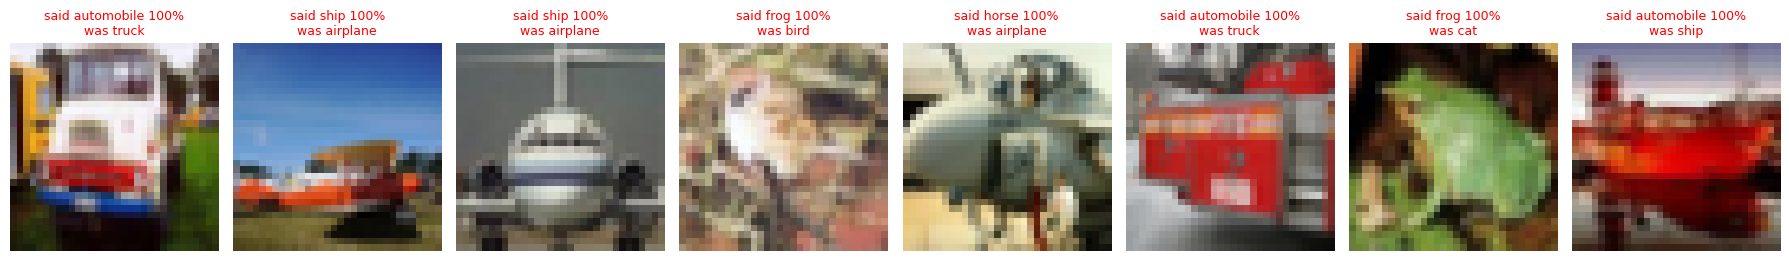

In [50]:
all_probs = model.predict(x_test, verbose=0)         # probabilities for all 10,000 test images
conf = all_probs.max(axis=1)                         # confidence = probability of the class it picked
wrong = predictions != y_test.ravel()                # True where the prediction was wrong
print(f"Average confidence when right: {conf[~wrong].mean():.0%}   when wrong: {conf[wrong].mean():.0%}")  # is confidence a useful signal?
print(f"Wrong predictions made with over 90% confidence: {(wrong & (conf > 0.9)).sum()} of {wrong.sum()}")  # confident mistakes
worst = np.argsort(-(conf * wrong))[:8]              # the 8 most confident wrong answers
fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))    # show them in a row
for ax, i in zip(axes, worst):  # each confident mistake
    ax.imshow(x_test[i]); ax.axis("off")  # show the image
    ax.set_title(f"said {LABEL_NAMES[predictions[i]]} {conf[i]:.0%}\nwas {LABEL_NAMES[y_test[i][0]]}", fontsize=9, color="red")  # what it said vs what it was
plt.tight_layout(); plt.show()  # tidy the spacing and draw

### 4. Save the trained model for the Unit 10 activity

In [51]:
model.save("cifar10_cnn.keras")                     # save the trained model so Unit 10 can reuse it without retraining
print("saved")  # confirm the save

saved


## What I took from it

- **64% on unseen images, and it stopped itself early.** Early stopping halted training after 7 of the 25
  epochs, because validation loss had been rising for two epochs. By then training accuracy was 74% and
  validation 64%, so the gap was opening up. That's overfitting starting, and early stopping caught it.
  64% sounds low, but there are 10 classes, so guessing would get 10%.
- **Images 1 to 16: 11 right, 5 wrong.** The module's default, image 16, is a dog, and it gets it right, but
  only at 54% confidence. The mistakes are telling. Two planes were called a ship and a cat, and a frog was
  called a deer at 91%. Planes and ships are both grey shapes on blue backgrounds, and at 32 by 32 pixels the
  background does a lot of the talking.
- **"Cat" is the model's dumping ground.** Dogs are its worst class (36% correct), and 361 of the 1,000 test
  dogs were called cats. Birds, deer and horses also get called cats more than anything else. Only 38% of its
  "cat" predictions are actually cats. Furry four-legged animals at this resolution look alike, and it has
  learned to default to one of them.
- **It is often confidently wrong.** It averages 83% confidence when right and 63% when wrong, so confidence
  carries some signal. But 381 of its 3,582 mistakes were made with over 90% confidence, like the frog called a
  deer. A confidence score is not a guarantee. If a system like this were used for anything that matters, for
  example flagging people or vehicles on camera, those confident mistakes are the ones nobody would think to
  double-check. I pick this up in my reflection on Wall (2019).